# Interpreting results

<!-- markdownlint-disable MD033-->
<div class="page-subtitle">
Interpreting super-resolved output and its uncertainty
</div>
<!-- markdownlint-enable MD033 -->

---

You produced a single super-resolved patch on the previous page. This page asks how confident the model actually was about the detail it generated, and, just as importantly, what that confidence measure does and does not prove.

---

## 1. Motivation

A super-resolved image looks equally sharp and finished everywhere, whether the model was genuinely confident about a given region or essentially guessing. Uncertainty estimation is what surfaces that hidden difference, and reading it correctly is one of the most important responsible-use skills in this entire lesson.

---

## 2. Core idea

Because the reverse diffusion process involves stochastic sampling, running the model multiple times on the same input with different random seeds produces slightly different outputs. The **{term}`uncertainty map <Uncertainty Map>`** is the standard deviation across those repeated runs, computed per pixel: pixels where repeated runs agree closely indicate higher model confidence, and pixels where they disagree substantially indicate the model is less certain about the fine-scale structure it generated there.

---

## 3. Computing and reading uncertainty

### A. Compute uncertainty

Start by loading the same Granada scene as on the previous page. If the file was already downloaded there, it is reused rather than downloaded again.

In [7]:
import geoai
from matplotlib import pyplot as plt
from pathlib import Path

DATA_DIR = Path("data/raw")
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR = Path("data/processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)

url = "https://data.source.coop/giuz/sds320/L09/data/S2A_L2A_20260802_N0512_R094_subset_Granada.tif"
s2_path = geoai.download_file(url, output_path=str(DATA_DIR / Path(url).name))

Then run super-resolution on the same 128-by-128 patch as before, this time with uncertainty estimation enabled:

In [8]:
sr_unc_output = str(OUT_DIR / "sr_with_uncertainty.tif")
unc_output = str(OUT_DIR / "uncertainty.tif")

sr_image2, uncertainty = geoai.super_resolution(
    input_lr_path=s2_path,
    output_sr_path=sr_unc_output,
    output_uncertainty_path=unc_output,
    rgb_nir_bands=[1, 2, 3, 4],
    window=(700, 1300, 128, 128),
    compute_uncertainty=True,
    n_variations=5,
    sampling_steps=100,
)

LatentDiffusion: Running in eps-prediction mode
DiffusionWrapper has 113.63 M params.
Keeping EMAs of 308.
making attention of type 'vanilla' with 512 in_channels
Working with z of shape (1, 4, 128, 128) = 65536 dimensions.
making attention of type 'vanilla' with 512 in_channels
Normalization disabled.
Loaded pretrained weights from:  /Users/wulf/.cache/torch/hub/checkpoints/opensr-ldsrs2_v1_0_0.ckpt


`compute_uncertainty=True` enables the repeated-sampling process; `n_variations=5` sets how many stochastic forward passes to run. More variations produce a smoother, more reliable uncertainty estimate, at a processing-time cost that scales roughly proportionally with `n_variations`.

### B. Visualize the uncertainty map

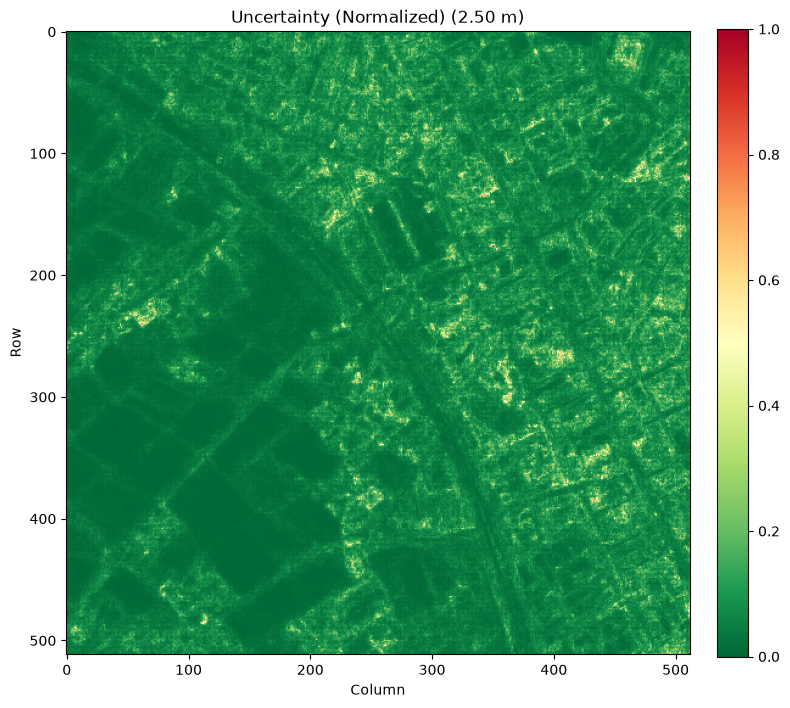

In [9]:
geoai.plot_sr_uncertainty(unc_output)
plt.show()

The visualization uses a color scale where green indicates low uncertainty (high confidence) and red or yellow indicates high uncertainty (low confidence), letting you see at a glance where the model's repeated guesses agreed and where they diverged.

### C. Reading uncertainty areas

High uncertainty tends to concentrate along sharp boundaries (building edges, road margins), in areas with complex fine-scale texture (dense vegetation canopies), and wherever the low-resolution input itself is ambiguous about what lies beneath. Homogeneous regions, open water, bare soil, uniform fields, typically show low uncertainty, simply because there is less fine-scale structure for the model to have to invent in the first place.

### D. What uncertainty does not tell you

```{admonition} Low uncertainty is not proof of correctness
:class: warning
A model can be confidently wrong: producing a sharp, consistent feature across every stochastic pass that nonetheless does not match what actually exists on the ground. Uncertainty tells you how consistent the model's repeated guesses were with each other, not whether any of them are correct. Treat a low-uncertainty region as "the model was consistent here," not as "this is verified."
```

---

## 4. Python reactivation

`n_variations=5` is simply an integer controlling how many times the function repeats its internal sampling loop; the underlying pattern, running the same computation multiple times and summarizing the results (here, with a standard deviation) is the same idea behind repeated experiments or bootstrapped estimates you may have seen in a statistics course.

---

## 5. Common pitfalls

- **Treating low uncertainty as proof of correctness.** This is the single most important pitfall in this lesson; low uncertainty means consistent, not necessarily correct.
- **Assuming all high-uncertainty regions represent errors.** Some genuinely are ambiguous, hard-to-resolve areas where caution is warranted; the map flags where to look carefully, not automatically what is wrong.
- **Choosing `n_variations` without considering the time cost.** More variations smooth the estimate but scale processing time proportionally; a course project may not need or afford a very high value.
- **Skipping uncertainty estimation entirely for a project deliverable.** If super-resolved imagery informs a project conclusion, the uncertainty map is part of the evidence needed to interpret that conclusion responsibly, not an optional add-on.

---

## 6. Mini task

You compute an uncertainty map for a patch containing a dense residential neighborhood and a large, uniform lake. Predict, before looking, which region will likely show higher uncertainty, and explain why using the ideas from this page.

:::{dropdown} Sample solution
:class: note

The residential neighborhood is likely to show higher uncertainty. It contains sharp boundaries (building edges, property lines) and fine-scale texture that the model must infer from a coarse input, exactly the conditions associated with high uncertainty described above. The uniform lake is homogeneous, with little fine-scale structure to reconstruct, so repeated stochastic passes are likely to agree closely there, producing low uncertainty.
:::

---

## 7. Key takeaways

- Uncertainty maps come from computing the standard deviation across multiple stochastic forward passes with different random seeds.
- High uncertainty tends to appear at sharp boundaries and complex textures; low uncertainty tends to appear in homogeneous regions.
- Low uncertainty means the model was consistent across runs, not that its output is verified correct; a model can be confidently wrong.
- `n_variations` trades estimate smoothness against processing time, the same kind of trade-off you have seen throughout this course.